# Introduction

To determine the best neighboorhood in Pittsburgh we though we should approach it using a quality of life metric. Basically, the better a person's experience living there is, the better the neighboorhood. We originally, used this main metric to draft 3 submetrics to breakdown quality of life into food, housing, and crime. In food we looked at the amount of restaurants there were in the neighboorhood where higher is better. In housing, we were going to look at the quality of the housing market, and the easier it is to buy a house the better. Finally, we were going to look at crime in the neighboorhood and here a lower rate is better. But, after listening to another groups idea we decided to be more creative. We decided change the main metric to quality of life for the steryotypical American. Then we switched the submetrics to food, health, and gun ownership and chose the anaylze with some steryotypes in mind. For food, we decided that a better neighboorhood for an American would be the place with the most fast food restaurants. For health, we thought the best neighboorhood would have highest obesity rate. Finally, for gun ownership, we though the best neighborhood in Pittsburgh would have the highest amount of gun seizures and by association, the most amount of guns.

# The Metric

My submetric is going to be health and I am going to specifcally look at obesity rate in Allegheny county. To relate it to the main metric of quality of life for an average American I am going to look for the neighboorhods with the highest obesity rates as Americans are often stereotypically considered obese and America is known for their obesity issues. The dataset I am going to look at is called "Allegheny County Obesity Rates" and specially process the csv called "Obesity Rates Allegheny County Data." (The link is https://data.wprdc.org/dataset/allegheny-county-obesity-rates.)

# Analysis for Best Neighborhood

In [34]:
# import starting boilerplate
import pandas as p
df = p.read_csv("obesity-ac-2006-2010censustracts.csv")

df_hoods = df["City Neighborhood"] # structure of all Neighboorhood listed
df_pitt = df[df_hoods.notna()] # notna() trims to just pitt only

# for all each hood find the mean for its obesity rate
pitt_mean_rates = df_pitt.groupby("City Neighborhood")["2006-2010 estimate of obesity"].mean()

# reset index converts labeled indexes to numerical index and the labels back to a column
# this allows sort to sort b/c it can only sort a column
sorted_pitt_rates = pitt_mean_rates.reset_index().sort_values('2006-2010 estimate of obesity', ascending=False) 

### Top 10 Most Obese Neighborhoods in Pittsburgh

In [35]:
sorted_pitt_rates.head(10)

,City Neighborhood,2006-2010 estimate of obesity
58,Northview Heights,0.922932
31,Fairywood,0.820311
14,California Kirkbride,0.771046
68,Saint Clair,0.699500
83,Terrace Village,0.674103
16,Central Business District,0.668012
6,Bedford Dwellings,0.636222
41,Homewood South,0.609697
50,Middle Hill,0.608099
40,Homewood North,0.596425


# Graph of Obesity Rates in Different Neighborhoods in Pittsburgh (Most -> Least)

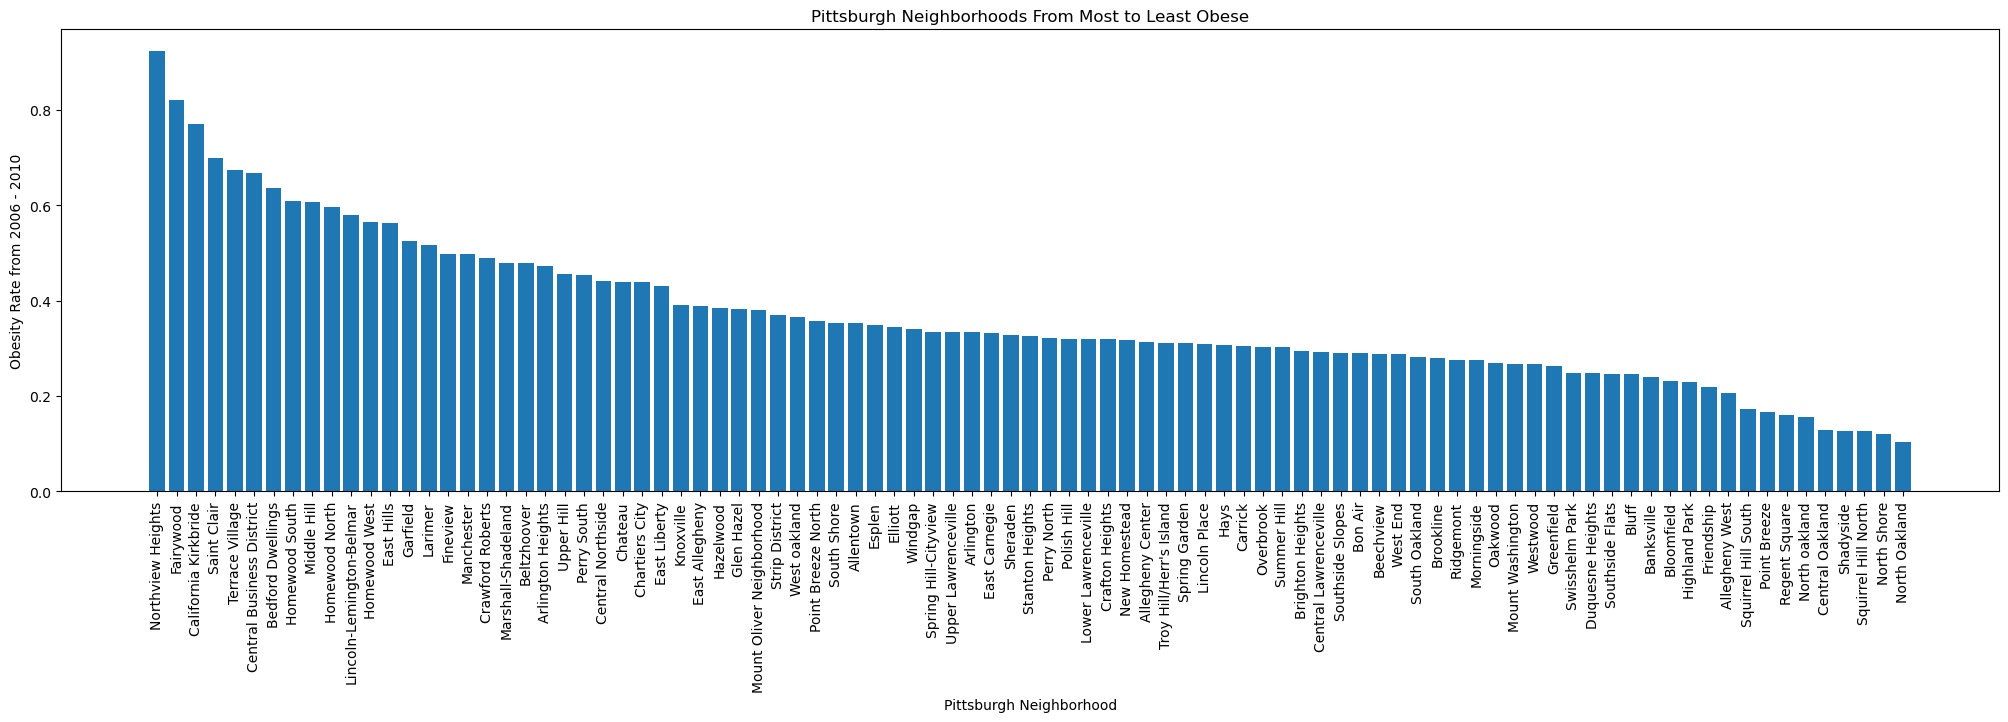

In [54]:
%matplotlib inline
import matplotlib.pyplot as plt

# A Figure is the main thing displayed on a graph
# figsize is width and height
plt.figure(figsize=(25, 6))

# Create the bar graph (names, vals)
plt.bar(sorted_pitt_rates["City Neighborhood"], sorted_pitt_rates["2006-2010 estimate of obesity"])
plt.xticks(rotation="vertical") # turn labels so they don't overlap

plt.xlabel("Pittsburgh Neighborhood")
plt.ylabel("Obesity Rate from 2006 - 2010")
plt.title("Pittsburgh Neighborhoods From Most to Least Obese")

plt.show()